# Lecture 10: Evaluating SciML

We evaluate the three Lecture 9 models (SmallCNN, ViT, ViT-local) and a baseline that needs no training.

1. **Metrics on a rollout**: relative L2 error and VRMSE for each field, correlation and high-correlation time, error by frequency band, against persistence.
2. **Double penalty**: score a sharp, displaced bubble and a blurred one.
3. **A quantity of interest**: the domain-mean temperature over the rollout.

The models are the trained Lecture 9 checkpoints; nothing is trained in this notebook.

In [1]:
import os
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
torch.manual_seed(0)

DATA_DIR = "../data/bubbleml"
FILE = "bubbleml2_Twall106_128.npz"
URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/bubbleml/"
os.makedirs(DATA_DIR, exist_ok=True)
if not os.path.exists(os.path.join(DATA_DIR, FILE)):
    print("downloading", FILE)
    urllib.request.urlretrieve(URL + FILE, os.path.join(DATA_DIR, FILE))

# temperature colormap from Lecture 1 (https://github.com/therml-ai/boiling-viz), for theta in [0, 1]
temp_cmap = LinearSegmentedColormap.from_list("temp_green", list(zip(
    [0.0, 0.02, 0.04, 0.06, 0.08, 0.1, 0.134, 0.167, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0],
    ["#0000FF", "#0443FF", "#0E7AFF", "#16B4FF", "#1FF1FF", "#21FFD3", "#22FF9B", "#22FF67", "#22FF15", "#29FF06",
     "#45FF07", "#6DFF08", "#9EFF09", "#D4FF0A", "#FEF30A", "#FEB709", "#FD7D08", "#FC4908", "#FC1407", "#FB0007"])))

Using device: mps


### The data and the models

BubbleML_2, subcooled pool boiling of FC-72 with a 106 °C heater, averaged to 64 × 64. Frames are 0.2 nondimensional time units apart.
Channels: $\theta = (T - 50\,°\mathrm{C})/(106\,°\mathrm{C} - 50\,°\mathrm{C})$ and the velocity $u, v$. Frames 0–599 are for training, 600–800 for testing.
The model code is the same as in Lecture 9.

In [2]:
d = np.load(os.path.join(DATA_DIR, FILE))
data = np.stack([d["temperature"], d["velx"], d["vely"]], axis=1).astype(np.float32)   # [frames, 3, 128, 128]
data = data.reshape(len(data), 3, 64, 2, 64, 2).mean(axis=(3, 5))                       # 2 x 2 average -> 64 x 64
train_np, test_np = data[:600], data[600:]
mu, sd = train_np.mean(axis=(0, 2, 3)), train_np.std(axis=(0, 2, 3))
du = train_np[1:] - train_np[:-1]
mu_du, sd_du = du.mean(axis=(0, 2, 3)), du.std(axis=(0, 2, 3))
train_t = torch.from_numpy(train_np)
print("train:", train_np.shape, "  test:", test_np.shape)

train: (600, 3, 64, 64)   test: (201, 3, 64, 64)


In [3]:
def attention(Q, K, V, mask=None):
    # Q: [..., N, dk], K: [..., N, dk], V: [..., N, dv]. Returns the outputs and the weights [..., N, N]
    scores = Q @ K.transpose(-2, -1) / Q.shape[-1] ** 0.5
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ V, weights


class Attention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.h = heads
        self.qkv = nn.Linear(d, 3 * d)
        self.out = nn.Linear(d, d)
        self.weights = None                        # attention weights of the last call, for plotting

    def forward(self, x, mask=None):               # x: [B, N, d]
        B, N, D = x.shape
        q, k, v = self.qkv(x).view(B, N, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)   # each [B, h, N, d/h]
        o, w = attention(q, k, v, mask)
        self.weights = w.detach()
        return self.out(o.transpose(1, 2).reshape(B, N, D))

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = Attention(d, heads)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask=None):
        x = x + self.attn(self.ln1(x), mask)       # Z = X + MHA(LN(X))
        return x + self.mlp(self.ln2(x))           # Y = Z + MLP(LN(Z))

class ViTBody(nn.Module):
    def __init__(self, c=3, n=64, p=4, d=64, depth=4, heads=4, radius=None):
        super().__init__()
        self.p, self.g = p, n // p                 # patch size, patches per side
        mask = None
        if radius is not None:                     # neighborhood attention: patches within `radius` in each direction
            yy, xx = torch.meshgrid(torch.arange(self.g), torch.arange(self.g), indexing="ij")
            yy, xx = yy.flatten(), xx.flatten()
            mask = ((yy[:, None] - yy[None]).abs() <= radius) & ((xx[:, None] - xx[None]).abs() <= radius)
        self.register_buffer("mask", mask, persistent=False)
        self.embed = nn.Conv2d(c, d, p, stride=p)  # patch embedding
        self.pos = nn.Parameter(0.02 * torch.randn(1, self.g ** 2, d))
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(depth)])
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, c * p * p)        # each token -> one p x p patch of c fields

    def forward(self, x):
        B, c = x.shape[0], x.shape[1]
        t = self.embed(x).flatten(2).transpose(1, 2) + self.pos            # [B, N, d]
        for blk in self.blocks:
            t = blk(t, self.mask)
        y = self.head(self.ln(t))                                           # [B, N, c p p]
        y = y.view(B, self.g, self.g, c, self.p, self.p).permute(0, 3, 1, 4, 2, 5)
        return y.reshape(B, c, self.g * self.p, self.g * self.p)

def smallcnn_body(cin=3, hidden=32, cout=3):
    cv = lambda i, o: nn.Conv2d(i, o, 3, padding=1)
    return nn.Sequential(cv(cin, hidden), nn.GELU(), cv(hidden, hidden), nn.GELU(), cv(hidden, hidden), nn.GELU(), cv(hidden, cout))

class Surrogate(nn.Module):
    def __init__(self, body):
        super().__init__()
        self.net = body
        self.register_buffer("mu", torch.tensor(mu).view(1, 3, 1, 1))
        self.register_buffer("sd", torch.tensor(sd).view(1, 3, 1, 1))
        self.register_buffer("mu_du", torch.tensor(mu_du).view(1, 3, 1, 1))
        self.register_buffer("sd_du", torch.tensor(sd_du).view(1, 3, 1, 1))

    def increment(self, x):                        # standardized change, the network's output
        return self.net((x - self.mu) / self.sd)

    def forward(self, x):                          # next state
        return x + self.mu_du + self.sd_du * self.increment(x)

for name, body in [("SmallCNN", smallcnn_body()), ("ViT", ViTBody())]:
    print(f"{name:8s} parameters: {sum(p.numel() for p in body.parameters()):,}")

SmallCNN parameters: 20,259
ViT      parameters: 222,704


In [4]:
CKPT_DIR = "../data/lecture09"
CKPT_URL = "https://raw.githubusercontent.com/eecs-ml4sci/eecs-ml4sci.github.io/main/data/lecture09/"

def load(body, name):
    path = os.path.join(CKPT_DIR, name)
    if not os.path.exists(path):
        os.makedirs(CKPT_DIR, exist_ok=True)
        print("downloading", name); urllib.request.urlretrieve(CKPT_URL + name, path)
    body.load_state_dict(torch.load(path, map_location="cpu"))
    return Surrogate(body).to(device).eval()

models = {"SmallCNN": load(smallcnn_body(), "smallcnn_4000.pt"),
          "ViT": load(ViTBody(), "vit_4000.pt"),
          "ViT-local": load(ViTBody(radius=2), "vit_local_4000.pt")}

---
## Part 1: Metrics on a rollout

**Persistence** predicts no change: $\hat u_{n+1} = u_n$. It is the simplest baseline and needs no training.

We roll each model out for 100 steps from the first test frame and keep all three fields.

In [5]:
STEPS = 100
truth = test_np[:STEPS + 1]                                   # [101, 3, 64, 64]

@torch.no_grad()
def rollout(model, steps=STEPS):
    s = torch.from_numpy(test_np[:1]).to(device); out = [test_np[0]]
    for n in range(steps):
        s = model(s)
        out.append(s[0].cpu().numpy())
    return np.stack(out)

rolls = {name: rollout(m) for name, m in models.items()}
rolls["persistence"] = np.repeat(test_np[:1], STEPS + 1, axis=0)
FIELDS = ["θ", "u", "v"]

### Relative L2 error and VRMSE

For a prediction $\hat u$ and reference $u$ on the grid,

$$\text{relative L2} = \frac{\|\hat u - u\|_2}{\|u\|_2}, \qquad \mathrm{VRMSE} = \sqrt{\frac{\mathrm{mean}\,(\hat u - u)^2}{\mathrm{var}\, u}}.$$

VRMSE divides by the variation of the field around its mean, so predicting the mean scores 1. Each function takes arrays `[steps, H, W]` and returns one value per step.

In [6]:
def rel_l2(pred, ref):                            # ||pred - ref||_2 / ||ref||_2 for each step
    d = (pred - ref).reshape(len(ref), -1); t = ref.reshape(len(ref), -1)
    return np.linalg.norm(d, axis=1) / np.linalg.norm(t, axis=1)

def vrmse(pred, ref):                             # sqrt(mean (pred - ref)^2 / var ref) for each step
    d = (pred - ref).reshape(len(ref), -1); t = ref.reshape(len(ref), -1)
    return np.sqrt(np.mean(d ** 2, 1) / (t.var(1) + 1e-12))

one step        θ relL2    θ VRMSE    u relL2    u VRMSE    v relL2    v VRMSE
SmallCNN          0.158      0.187      0.169      0.174      0.132      0.132
ViT               0.217      0.256      0.213      0.218      0.164      0.164
ViT-local         0.222      0.262      0.216      0.221      0.167      0.167
persistence       0.341      0.403      0.300      0.307      0.218      0.218


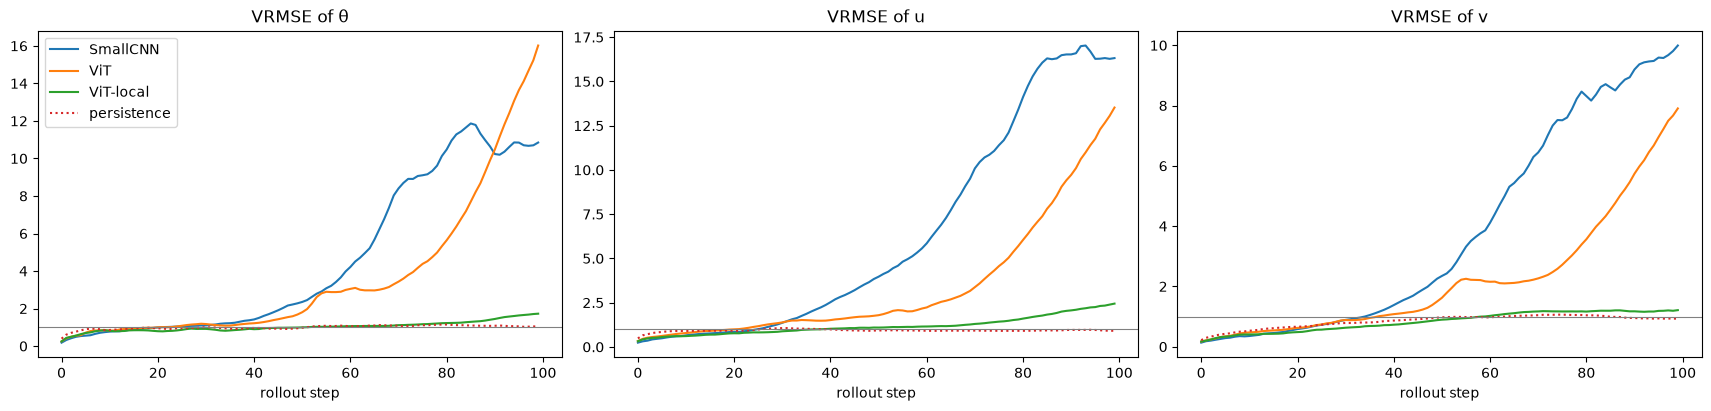

In [7]:
# one-step error on all test frames (the Lecture 9 number), and persistence
@torch.no_grad()
def one_step(model):
    x = torch.from_numpy(test_np[:-1]).to(device)
    return torch.cat([model(x[i:i + 50]) for i in range(0, len(x), 50)]).cpu().numpy()

preds = {name: one_step(m) for name, m in models.items()}
preds["persistence"] = test_np[:-1]
print(f"{'one step':12s}" + "".join(f"{f + ' relL2':>11s}{f + ' VRMSE':>11s}" for f in FIELDS))
for name, p in preds.items():
    row = "".join(f"{rel_l2(p[:, c], test_np[1:, c]).mean():11.3f}{vrmse(p[:, c], test_np[1:, c]).mean():11.3f}" for c in range(3))
    print(f"{name:12s}" + row)

fig, ax = plt.subplots(1, 3, figsize=(17, 4), layout="constrained")
for c, a in enumerate(ax):
    for name, r in rolls.items():
        a.plot(np.arange(1, STEPS + 1), vrmse(r[1:, c], truth[1:, c]), label=name, ls=":" if name == "persistence" else "-")
    a.axhline(1, color="gray", lw=0.8); a.set_title(f"VRMSE of {FIELDS[c]}"); a.set_xlabel("rollout step")
ax[0].legend(); plt.show()

**What to observe**

* At one step every model beats persistence on all three fields. SmallCNN, with a tenth of the ViT's parameters, is the most accurate (slide on data size).
* Over the rollout the ranking changes. SmallCNN and ViT pass persistence after about 30 steps and grow far above 1. ViT-local stays close to persistence the longest.
* A VRMSE above 1 is worse than predicting the mean field everywhere. Persistence settles near 1: an old frame is about as good as the mean.

### Correlation and high-correlation time

The correlation of the prediction with the reference at each step is $\rho = \langle \hat u - \overline{\hat u},\, u - \bar u\rangle / (\|\hat u - \overline{\hat u}\|_2 \|u - \bar u\|_2)$, where the bar is the mean over the grid.
The high-correlation time is the first step at which $\rho$ drops below a threshold.

SmallCNN     steps until ρ(θ) < 0.9:    4    < 0.8:    8
ViT          steps until ρ(θ) < 0.9:    3    < 0.8:    6
ViT-local    steps until ρ(θ) < 0.9:    3    < 0.8:    5
persistence  steps until ρ(θ) < 0.9:    2    < 0.8:    3


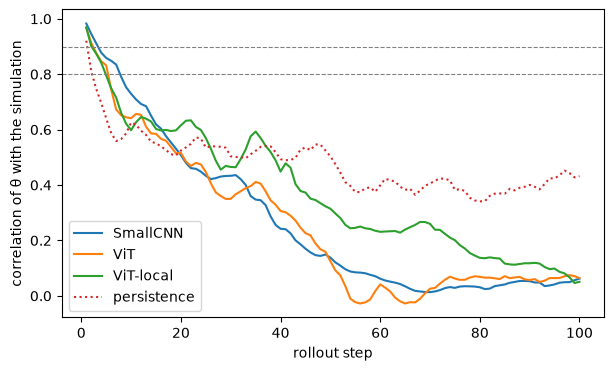

In [8]:
def corr(pred, ref):
    a = pred.reshape(len(pred), -1); b = ref.reshape(len(ref), -1)
    a = a - a.mean(1, keepdims=True); b = b - b.mean(1, keepdims=True)
    return (a * b).sum(1) / np.sqrt((a ** 2).sum(1) * (b ** 2).sum(1))

def high_corr_time(rho, thr):
    below = np.nonzero(rho < thr)[0]
    return below[0] + 1 if len(below) else None                # rho[0] is step 1; None: never

fig, ax = plt.subplots(figsize=(7, 4))
for name, r in rolls.items():
    rho = corr(r[1:, 0], truth[1:, 0])
    ax.plot(np.arange(1, STEPS + 1), rho, label=name, ls=":" if name == "persistence" else "-")
    print(f"{name:12s} steps until ρ(θ) < 0.9: {high_corr_time(rho, 0.9)!s:>4}    < 0.8: {high_corr_time(rho, 0.8)!s:>4}")
for thr in (0.8, 0.9): ax.axhline(thr, color="gray", lw=0.8, ls="--")
ax.set_xlabel("rollout step"); ax.set_ylabel("correlation of θ with the simulation"); ax.legend(); plt.show()

**What to observe**

* The 0.8 and 0.9 thresholds give the same order: SmallCNN stays correlated longest, then ViT, ViT-local and persistence. 
* Every model drops below 0.8 within a few steps, about one time unit. A small one-step error does not give a long high-correlation time.
* Persistence falls fastest at first, then levels off and stays above every model for the second half of the rollout. The heater, the plume and the nucleation sites stay in place, so a frozen frame remains partly correlated with the flow.

### Error by frequency band

As in The Well, split the 2D spectrum into three bands of the radial wavenumber $k$ with boundaries evenly spaced in $\log k$, and divide the error energy in each band by the true energy in that band. A value near 1 means the band is lost.

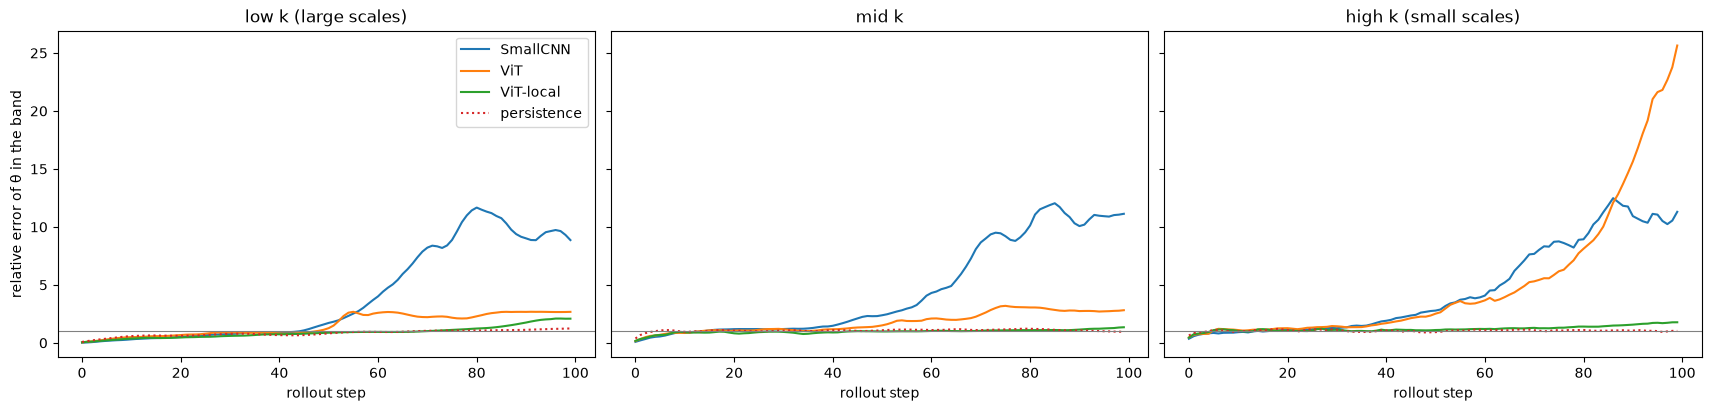

In [9]:
def band_error(pred, ref, nbins=3):
    n = ref.shape[-1]
    k = np.fft.fftfreq(n) * n
    kr = np.sqrt(k[:, None] ** 2 + k[None, :] ** 2)
    edges = np.logspace(0, np.log10(kr.max() + 1e-9), nbins + 1); edges[0] = 0.5        # skip the mean (k = 0)
    E_err = np.abs(np.fft.fft2(pred - ref)) ** 2
    E_ref = np.abs(np.fft.fft2(ref)) ** 2
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (kr >= lo) & (kr < hi)
        out.append(np.sqrt(E_err[..., m].sum(-1) / E_ref[..., m].sum(-1)))
    return np.stack(out, -1)                                   # [steps, bands]: low, mid, high

fig, ax = plt.subplots(1, 3, figsize=(17, 4), layout="constrained", sharey=True)
for b, (a, band) in enumerate(zip(ax, ["low k (large scales)", "mid k", "high k (small scales)"])):
    for name, r in rolls.items():
        a.plot(np.arange(1, STEPS + 1), band_error(r[1:, 0], truth[1:, 0])[:, b], label=name, ls=":" if name == "persistence" else "-")
    a.axhline(1, color="gray", lw=0.8); a.set_title(band); a.set_xlabel("rollout step")
ax[0].set_ylabel("relative error of θ in the band"); ax[0].legend(); plt.show()

**What to observe**

* The high band (small scales) reaches 1 within a few steps. The low band (large scales) stays below 1 for about 40 steps. Small scales are lost first, as in the spectra of Lectures 6 and 7.
* Most of the energy of θ is at low k, so the total VRMSE (Part 1) follows the low band early in the rollout and hides the loss of the small scales.

---
## Part 2: Double penalty

A bubble on a 128 × 128 grid. A sharp prediction displaced by $\delta$ and a blurred one (the mean of the bubble over shifts in $[-\delta, \delta]$). Which has the lower RMSE?

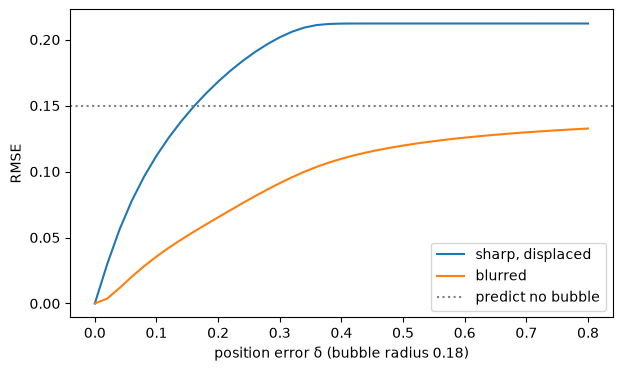

In [10]:
n = 128; x = np.linspace(-1, 1, n); X, Y = np.meshgrid(x, x)
def bubble(cx, r0=0.18): return 0.5 * (1 - np.tanh((np.hypot(X - cx, Y) - r0) / 0.02))
truth_b = bubble(0.0)
rmse = lambda a: np.sqrt(np.mean(a ** 2))

deltas = np.linspace(0, 0.8, 41)
sharp = [rmse(bubble(d) - truth_b) for d in deltas]
blur = [rmse(np.mean([bubble(c) for c in np.linspace(-d, d, 41)], 0) - truth_b) for d in deltas]
plt.figure(figsize=(7, 4))
plt.plot(deltas, sharp, label="sharp, displaced"); plt.plot(deltas, blur, label="blurred")
plt.axhline(rmse(truth_b), color="gray", ls=":", label="predict no bubble")
plt.xlabel("position error δ (bubble radius 0.18)"); plt.ylabel("RMSE"); plt.legend(); plt.show()

**What to observe**

* Once $\delta$ exceeds the bubble size, the sharp prediction has RMSE $\sqrt 2$ times that of predicting no bubble: its error is counted where the bubble should be and again where it is.
* The blurred prediction has a lower RMSE at every $\delta$. This is why MSE training produces blurred predictions when the position is uncertain.

---
## Part 3: A quantity of interest

The domain-mean temperature $\bar\theta$ measures the thermal energy in the domain. Its change is set by the heat from the heater and the heat that leaves through the outflow. A model with a small pointwise error can still drift in $\bar\theta$.

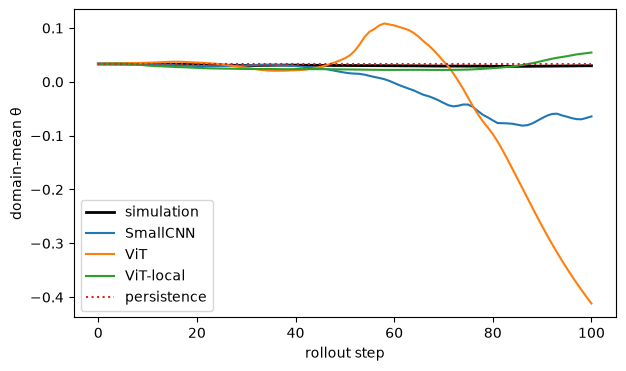

In [11]:
plt.figure(figsize=(7, 4))
plt.plot(truth[:, 0].mean(axis=(1, 2)), color="k", lw=2, label="simulation")
for name, r in rolls.items():
    plt.plot(r[:, 0].mean(axis=(1, 2)), label=name, ls=":" if name == "persistence" else "-")
plt.xlabel("rollout step"); plt.ylabel("domain-mean θ"); plt.legend(); plt.show()

**What to observe**

* The simulation keeps $\bar\theta$ nearly constant: the heat from the heater balances the heat that leaves through the outflow.
* SmallCNN, the most accurate model at one step, drifts down after about 40 steps and ends below zero, colder than the bulk liquid. The ViT overshoots and then falls further. ViT-local stays closest, with a slow rise near the end.
* A steady drift comes from a small bias at each step that adds up over the rollout.

---
## Exercises

1. **Divergence of the velocity.** The liquid is nearly incompressible away from the interfaces. Compute $\nabla\cdot\mathbf u = \partial u/\partial x + \partial v/\partial y$ with central differences (cell size 0.25) for the simulation and for each rollout. Plot its RMS over the rollout. Which model violates the constraint most?
2. **Kuramoto–Sivashinsky.** Use the solver below. Start two runs $10^{-4}$ apart and plot their correlation and relative L2 error against time. Then run both for 2000 time units and compare the mean, variance, PDF of $u$ and the energy spectrum. Which quantities agree?
3. **Threshold sensitivity.** Using the Part 1 rollouts, recompute the high-correlation time of θ with thresholds 0.7, 0.8, 0.9 and 0.95. Does the ranking of SmallCNN, ViT, ViT-local and persistence change?
4. **Double penalty in Fourier space.** Compute the energy spectrum (Lecture 6) of the truth, the sharp displaced bubble and the blurred bubble for $\delta = 0.5$. Which prediction has the right spectrum? Which metric would you use to prefer it?

In [12]:
# Exercise 1 starter
def divergence(u, v, h=0.25):
    # TODO: central differences in x (last axis) and y (second-to-last axis); return an array of the same shape
    raise NotImplementedError

In [13]:
# Exercise 2 starter: KS equation u_t + u u_x + u_xx + u_xxxx = 0 on a periodic domain of length 22 (ETDRK4, Kassam & Trefethen 2005)
L_ks, N_ks, dt_ks = 22.0, 64, 0.25
x_ks = L_ks * np.arange(N_ks) / N_ks
k_ks = 2 * np.pi / L_ks * np.fft.fftfreq(N_ks, 1 / N_ks)
Lin = k_ks ** 2 - k_ks ** 4
E, E2 = np.exp(dt_ks * Lin), np.exp(dt_ks * Lin / 2)
r = np.exp(1j * np.pi * (np.arange(1, 33) - 0.5) / 32); LR = dt_ks * Lin[:, None] + r[None, :]
Q  = dt_ks * np.real(np.mean((np.exp(LR / 2) - 1) / LR, 1))
f1 = dt_ks * np.real(np.mean((-4 - LR + np.exp(LR) * (4 - 3 * LR + LR ** 2)) / LR ** 3, 1))
f2 = dt_ks * np.real(np.mean((2 + LR + np.exp(LR) * (LR - 2)) / LR ** 3, 1))
f3 = dt_ks * np.real(np.mean((-4 - 3 * LR - LR ** 2 + np.exp(LR) * (4 - LR)) / LR ** 3, 1))
g = -0.5j * k_ks; g[N_ks // 2] = 0

def ks_step(vh):                                   # vh: Fourier coefficients of u
    nl = lambda w: g * np.fft.fft(np.real(np.fft.ifft(w)) ** 2)
    Nv = nl(vh); a = E2 * vh + Q * Nv; Na = nl(a); b = E2 * vh + Q * Na; Nb = nl(b)
    c = E2 * a + Q * (2 * Nb - Nv); Nc = nl(c)
    w = E * vh + Nv * f1 + 2 * (Na + Nb) * f2 + Nc * f3
    return np.fft.fft(np.real(np.fft.ifft(w)))    # keep u real

def ks_run(u0, T):
    vh = np.fft.fft(u0); out = [u0]
    for _ in range(int(T / dt_ks)):
        vh = ks_step(vh); out.append(np.real(np.fft.ifft(vh)))
    return np.array(out)

rng = np.random.default_rng(0)
u0 = ks_run(0.1 * np.cos(2 * np.pi * x_ks / L_ks) + 0.01 * rng.standard_normal(N_ks), 1000)[-1]   # past the transient
# TODO: run1 = ks_run(u0, 250); run2 = ks_run(u0 + 1e-4 * rng.standard_normal(N_ks), 250); compare